# Modelagem

Nesta etapa treinamos e comparamos classificadores para separar vinhos de alta qualidade (`quality >= 7`, classe 1) dos de baixa/média qualidade (classe 0).

Todos os modelos usam os mesmos arquivos de treino e teste salvos na etapa 3 (`etapa_3/resultados`), com `test_size=0.2`, `stratify` e `random_state=42`. A escolha de parâmetros é feita só no treino, com validação cruzada estratificada de 5 folds; o teste fica para a avaliação final.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

# Localizando a raiz do repositório para abrir o notebook daqui ou da raiz
raiz = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / "src").exists())
sys.path.append(str(raiz / "src"))

## Gradient Boosting

O Gradient Boosting cria várias árvores pequenas em sequência. Cada nova árvore tenta corrigir os erros das anteriores.

O que foi feito (código em `src/gradient_boosting.py`):

- **Pré-processamento:** a mesma pipeline da etapa 3, com `RobustScaler` antes do classificador. Para árvores a escala não muda o resultado, mas mantemos a mesma estrutura dos outros modelos.
- **Desbalanceamento:** o `GradientBoostingClassifier` não tem `class_weight`, então usamos `sample_weight` com `compute_sample_weight("balanced")`. Os pesos são calculados dentro do `fit`, ou seja, apenas com os dados de treino de cada ajuste (inclusive em cada fold da validação cruzada).
- **Baseline:** parâmetros padrão do scikit-learn, já com os pesos.
- **Ajuste:** `GridSearchCV` com uma grade pequena (`n_estimators`, `learning_rate`, `max_depth`, `subsample`; 16 combinações), `StratifiedKFold` de 5 folds e F1 da classe 1 como critério.

In [2]:
from gradient_boosting import executar

metricas, melhores, importancias = executar(raiz / "results" / "gradient_boosting")
print("Melhores hiperparâmetros:", melhores)
display(metricas.round(3))

Melhores hiperparâmetros: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}


,f1_cv_treino,accuracy,precision_1,recall_1,f1_1,roc_auc,average_precision,tn,fp,fn,tp
modelo,,,,,,,,,,,
baseline,0.511,0.873,0.514,0.704,0.594,0.902,0.601,159.0,18.0,8.0,19.0
ajustado,0.527,0.868,0.500,0.778,0.609,0.916,0.676,156.0,21.0,6.0,21.0


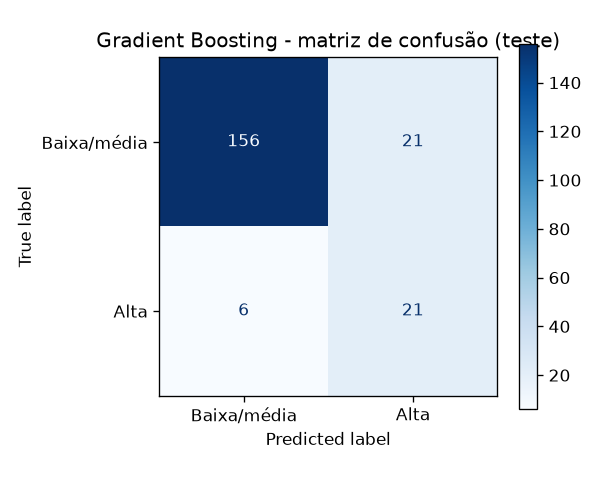

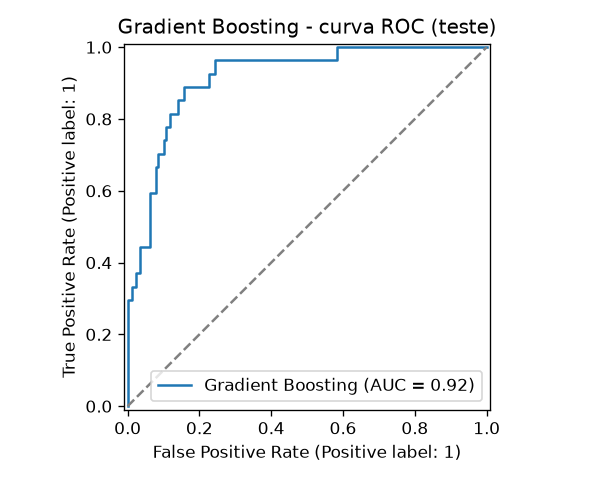

In [3]:
pasta_gb = raiz / "results" / "gradient_boosting"
display(Image(pasta_gb / "matriz_confusao.png"))
display(Image(pasta_gb / "curva_roc.png"))

### Resultados no teste

| Modelo | F1 CV (treino) | Accuracy | Precision 1 | Recall 1 | F1 1 | ROC-AUC |
|---|---|---|---|---|---|---|
| Baseline | 0,511 | 0,873 | 0,514 | 0,704 | 0,594 | 0,902 |
| Ajustado | 0,527 | 0,868 | 0,500 | 0,778 | 0,609 | 0,916 |

Melhores hiperparâmetros: `learning_rate=0.05`, `max_depth=3`, `n_estimators=100`, `subsample=0.8`.

- O ajuste melhorou pouco o F1 na validação cruzada e no teste. O ganho maior foi no recall: o modelo ajustado encontrou 21 dos 27 vinhos de alta qualidade do teste (o baseline encontrou 19).
- A precisão da classe 1 fica perto de 50%: metade dos vinhos apontados como alta qualidade são, na verdade, de baixa/média. Isso é esperado com os pesos balanceados, que favorecem o recall.
- O ROC-AUC acima de 0,9 mostra que o modelo ordena bem os vinhos pela probabilidade de alta qualidade.
- O teste tem só 27 vinhos da classe 1, então uma diferença de 1 ou 2 acertos muda bastante as métricas. Também vale lembrar a limitação da etapa 3: a EDA usou a base inteira.

### Importância das variáveis

Usamos o `feature_importances_` do modelo ajustado. Esses valores serão retomados na etapa 6.

,importancia
variavel,
alcohol,0.368
volatile acidity,0.167
sulphates,0.105
chlorides,0.070
fixed acidity,0.069
citric acid,0.067
total sulfur dioxide,0.044
density,0.036
free sulfur dioxide,0.028


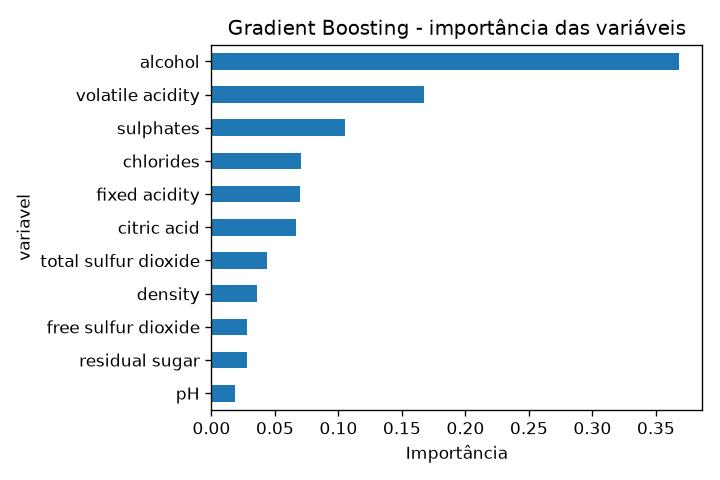

In [4]:
display(importancias.round(3).to_frame())
display(Image(pasta_gb / "importancia_variaveis.png"))

O teor alcoólico é a variável mais usada pelo modelo, seguido da acidez volátil e dos sulfatos, o que combina com o que vimos na EDA. Essa importância mostra o quanto cada variável ajudou nas divisões das árvores, mas não indica se o efeito aumenta ou diminui a chance de alta qualidade.